# Phyloseq-working

## 10.17.26 | tidy metadata

### Setting up R/phyloseq with conda environment in unity

Add phyloseq to `dada2-env` in terminal
```
conda activate dada2-env
conda install -c bionconda bioconda-phyloseq
```

### Metadata tidying

In [ ]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(Biostrings)
    library(tidyverse)
})

In [ ]:
# Read 16S processing tracker csv
meta16S <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/16S_tracker.csv")
dim(meta16S)
head(meta16S)

In [ ]:
# Tidy data
meta16S <- meta16S %>% 
                mutate(Original_order = NULL) %>%
                # Un-concatenate sample name
                separate(Sample_name,  into = c("Year", "Phase_1_treat", "Phase_2_treat", "Tag"), sep = "_", remove = FALSE) %>%
                # Add tissue type to sample name to match ASV table
                mutate(Sample_name = paste0(Sample_name, sep = "_", Tissue)) %>%
                # Separate the treatment and replicate into two columns
                extract(Phase_1_treat, into = c("Phase_1_treat", "Phase_1_rep"), regex = "([A-Za-z]+)([0-9]+)") %>%
                extract(Phase_2_treat, into = c("Phase_2_treat", "Phase_2_rep"), regex = "([A-Za-z]+)([0-9]+)") %>%
                # Add column for treatment combination
                mutate(Combined_treat = paste0(Phase_1_treat, Phase_2_treat)) %>%
                mutate(Combined_treat = gsub("[^A-Z]", "", Combined_treat)) %>%
                relocate(Combined_treat, .after = Year) %>%
                # Make the treatment replicate an integer rather than a string
                mutate(Phase_1_rep = as.integer(Phase_1_rep)) %>%
                mutate(Phase_2_rep = as.integer(Phase_2_rep)) %>%
                # Rename some columns
                rename(Date = X16S_date) %>%
                rename(Adapters = X16S_adapters) %>%
                # Format dates
                mutate(Date = as.Date(Date, format = "%m/%d/%y")) %>%
                mutate(Index_date = as.Date(Index_date, format = "%m/%d/%y"))
head(meta16S)

In [ ]:
# Check warning message
meta16S[239:247,]
meta16S[280:283,]
# Missing pieces are control samples

In [ ]:
# Remove empty rows 282, 283
meta16S <- meta16S[-282:-283,]
tail(meta16S)

In [ ]:
# Save tided csv
write.csv(meta16S, "/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=FALSE)

## 10.18.26 | phyloseq on decipher taxonomy

In [ ]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(Biostrings)
    library(tidyverse)
})

In [50]:
# Read ASV table
asvTable <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim_2.rds")

# Read taxonomy table
taxaDecipher <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/decipher_taxa_sp.rds")

# Read tidied metadata
sampleMetadata <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=1)

In [ ]:
# Check that row names are identical
head(asvTable)
head(sampleMetadata)

In [51]:
# Rearrange metadata sample order to match ASV table sample order
sampleMetadata <- sampleMetadata[match(rownames(asvTable), rownames(sampleMetadata)), ]
head(asvTable)
head(sampleMetadata)

,GAAGGGGGCGAGCGTTGTTCGGAATTACTGGGCGTAAAGGGCGTCTAGGTGGTTTTGTTAGTTGGATGTGAAAGCCCTCGGCTCAACCGAGGAATTGCATCCAAAACTGCATTACTAGAGTGTGAAAGGGGAAGGCGGAATTCCAAGTGTAGCGGTGAAATGCGTAGATATTTGGAGGAACACCGGTGGCGAAGGCGGCCTTCTGGTTCAACACTGACACTAAAGCGCGAAGGCTAGGGGAGCGAAC,GAAGGGGGCAAGCGTTGTTCGGAATTACTGGGCGTAAAGAGTACGTAGGCGGTTAGATTAGTTAGGTGTGAAATCCCGGAGCTCAACTTCGGAGTTGCACTTAATACTGTTTAACTAGAATTCAAGAGGGGAGAGTGGAATTTCCAGTGTAGGGGTGATATCCGTAGATATTGGAAGGAACATCAGAGGCGAAGGCGACTCTCTGGCTTGACATTGACGCTGAGGTACGAAAGCGTGGGTAGCAAAC,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTTGTAAGTCTGTTGTTAAAGCGTGGAGCTTAACTCCATTTCAGCAATGGAAACTGTAAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGAGGCTCAACTTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAAT,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTGTCAAGTCTGCTGTTAAAGCGTGGAGCTTAACTCCATTTCGGCAGTGGAAACTGACAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGGGGCGAGCGTTATTCGGAATTATTGGGTGTAAAGTGTGCGTAGGCGGCTTAGTAAGTTAATGGTGAAATCCCGGGGCTCAACCCCGGGGCTGCTTTTAGAACTGCTAAGCTGGAGTTGGAAAGAGGATAGCAGAATTCCTAGTGTAGAGGTGAAATTCGTAGATATTAGGAGGAATACCGGAGGCGAAGGCGGCTGTCTGGTTCCATACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GGAGGGTGCAAGCGTTACTCGGAATTACTGGGCGTAAAGGGTGCGTAGGCGTCTTATTAAGTCAGATGTGAAATCCTGTGGCTCAACCATAGAACTGCATTTGAAACTGGTAAGATAGAGTTCAGAAGGGGCAAGTGGAATTAGTGGTGTAGGGGTAAAATCCGTAGATATCACTAGGAATACCAAAAGCGAAGGCGACTTGCTAGGATGACACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GTAGGTCCCAAGCGTTATCCGGAATTATTGGGCGTAAAGGGTCCGTAGACGGTTTATTAAGTCTGATGTGAAAGCCACCGGCTCAACCGGTGAAACGCATTAGATACTGGTAAACTAGAGTATGTTAGAGGATAGTGGAATTCCATGTGTAGCGGTGAAATGCGTAGATATATGGAGGAACACCAGTGGCGAAGGCGGCTATCTGGGACATTACTGACGTTGAGGGACGAAAGCGTGGGGAGCGAAC,GAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGATGGCTCAACCTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAA,AACCAAGCGAACGTTATTCGGAATTACTGGGCTTAAAGCGCGTGTAGGCGGATTGCCACGTCGGCTGTTGAAATCCCCCGGCTCAACCGGGGAACAGGCACCGATACGAGTGATCTTGAGGTGGGTAGGGGAGACTGGAACTTCCGGTGGAGCGGTGAAATGCGTTGAGATCGGAAGGAACGCCCGCGGCGAAAGCGAGTCTCTGGCCCCATACTGACGCTGAGACGCGAAAGCCAGGGGAGCAAA,⋯,ATCTTACGGATGGCATGACAGTAAGAGAATTATGCAGTGCTGCCATAACCATGAGTGATAACACTGCGGCCAACTTACTTCTGACAACGATCGGAGGACCGAAGGAGCTAACCGCTTTTTTGCACAACATGGGGGATCATGTAACTCGCCTTGATCGTTGGGAACCGGAGCTGAATGAAGCCATACCAAACGACGAGCGTGACACCACGATGCCTGTAGCAATGGCAACAACGTTGCGCAAA,GGTCGTTCGGCTGCGGCGAGCGGTATCAGCTCACTCAAAGGCGGTAATACGGTTATCCACAGAATCAGGGGATAACGCAGGAAAGAACATGTGAGCAAAAGGCCAGCAAAAGGCCAGGAACCGTAAAAAGGCCGCGTTGCTGGCGTTTTTCCATAGGCTCCGCCCCCCTGACGAGCATCACAAAAATCGACGCTCAAGTCAGAGGTGGCGAAACCCGACAGGACTATAAAGATACCAGGCGTTTCCCCCTGGAAGCTCCCTCGTGCGCTCTCC,CTCATCATTGGAAAACGTTCTTCGGGGCGAAAACTCTCAAGGATCTTACCGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAA,AAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAAAAATAAACAAATAGGGGTTCCGCGCACATTTCCCCGAAAAGTGCCACCTGACGTCTAAGAAACCATTATTATCATGACATTAACCTATAAAAATAGGCGTATCACGAGGCCCTTTCGTCTCGCGCGTTTCGGTGATGACGGT,CCAGATTTATCAGCAATAAACCAGCCAGCCGGAAGGGCCGAGCGCAGAAGTGGTCCTGCAACTTTATCCGCCTCCATCCAGTCTATTAATTGTTGCCGGGAAGCTAGAGTAAGTAGTTCGCCAGTTAATAGTTTGCGCAACGTTGTTGCCATTGCTACAGGCATCGTGGTGTCACGCTCGTCGTTTGGTATGGCTTCATTCAGCTCCGGTTCCCAACGATCAAGGCGAGTTACATGATCCCCCATGTT,CGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGT

,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,Phase,Tissue,Concentration,⋯,Pooled_notes,Index_primers,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes
,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<int>,<chr>,<dbl>,⋯,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
2024_Both01_Both01_O1_gill,2024,BB,Both,1,Both,1,O1,2,gill,18.100,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,6.66,3.75,
2024_Both01_Both01_O1_gut,2024,BB,Both,1,Both,1,O1,2,gut,43.000,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,8.24,3.03,
2024_Both01_Null_O03_gill,2024,BNA,Both,1,NA,NA,O03,1,gill,0.980,⋯,,BFi-13,2026-07-08,3,7/10/26,,7/22/26,4.98,5.02,
2024_Both01_Null_O03_gut,2024,BNA,Both,1,NA,NA,O03,1,gut,0.886,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,5.80,4.31,Diluted final sample 1:3
2024_Both01_Warm05_O50_gill,2024,BW,Both,1,Warm,5,O50,2,gill,75.200,⋯,,BFi-13,2026-07-06,1,7/6/26,NA,NA,10.07,2.48,Diluted final sample 1:3
2024_Both01_Warm05_O50_gut,2024,BW,Both,1,Warm,5,O50,2,gut,46.900,⋯,,BFi-15,2026-07-03,2,7/3/26,NA,NA,7.40,3.38,Diluted final sample 1:3


In [ ]:
# Create phyloseq object
psObject <- phyloseq(otu_table(asvTable, taxa_are_rows = FALSE),
                     sample_data(sampleMetadata),
                     tax_table(taxaDecipher))
psObject

In [ ]:
# Extract ASV sequences
dna <- Biostrings::DNAStringSet(taxa_names(psObject))
names(dna) <- taxa_names(psObject)

# Create reference sequence component of phyloseq object to store the raw ASVs
psObject <- merge_phyloseq(psObject, dna)

# Rename ASVs numerically
taxa_names(psObject) <- paste0("ASV", seq(ntaxa(psObject)))

In [ ]:
# View and save object
psObject
saveRDS(psObject, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/psObject.rds")

## 10.20.26 | plots!

In [ ]:
plot_richness(ps, x="Combined_treat", measures=c("Shannon", "Simpson"), color="Phase")

In [74]:
ps.prop <- transform_sample_counts(ps_sub, function(otu) otu/sum(otu))
ord.nmds.bray <- ordinate(ps.prop, method="NMDS", distance="bray")

Run 0 stress 0.1538333 
Run 1 stress 0.1552541 
Run 2 stress 0.1896792 
Run 3 stress 0.1555948 
Run 4 stress 0.1555948 
Run 5 stress 0.1552541 
Run 6 stress 0.1535124 
... New best solution
... Procrustes: rmse 0.01043438  max resid 0.073201 
Run 7 stress 0.1646217 
Run 8 stress 0.1556833 
Run 9 stress 0.1552541 
Run 10 stress 0.1677257 
Run 11 stress 0.1638807 
Run 12 stress 0.1606776 
Run 13 stress 0.1627264 
Run 14 stress 0.1535124 
... New best solution
... Procrustes: rmse 2.048658e-05  max resid 0.0001009637 
... Similar to previous best
Run 15 stress 0.1555949 
Run 16 stress 0.1552541 
Run 17 stress 0.1603381 
Run 18 stress 0.1552541 
Run 19 stress 0.1829705 
Run 20 stress 0.1638781 
*** Best solution repeated 1 times


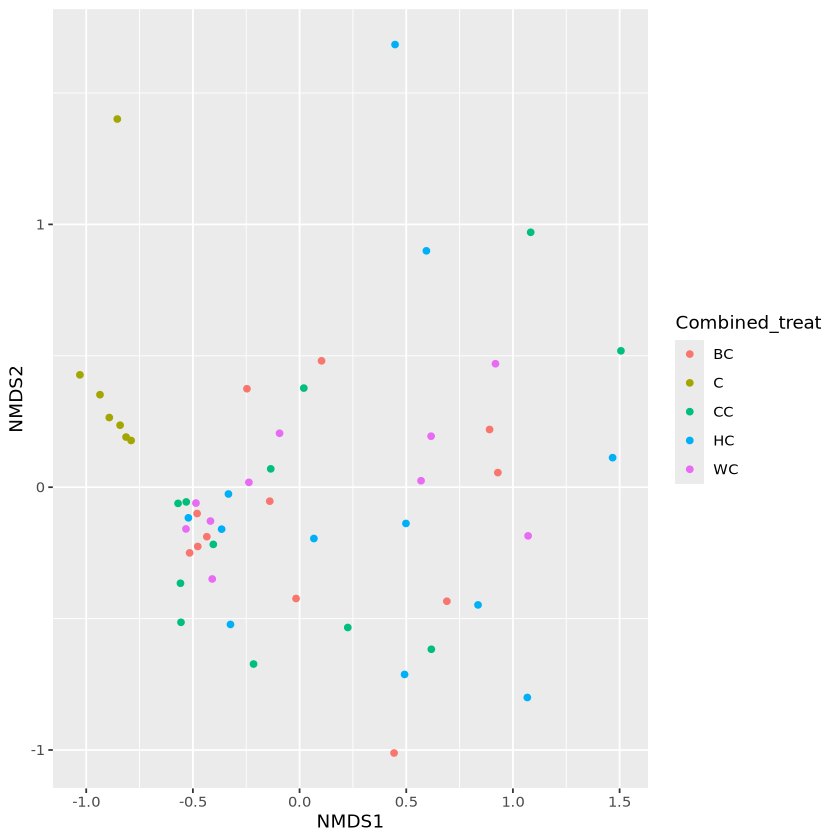

In [76]:
plot_ordination(ps.prop, ord.nmds.bray, type="samples", color="Combined_treat" )

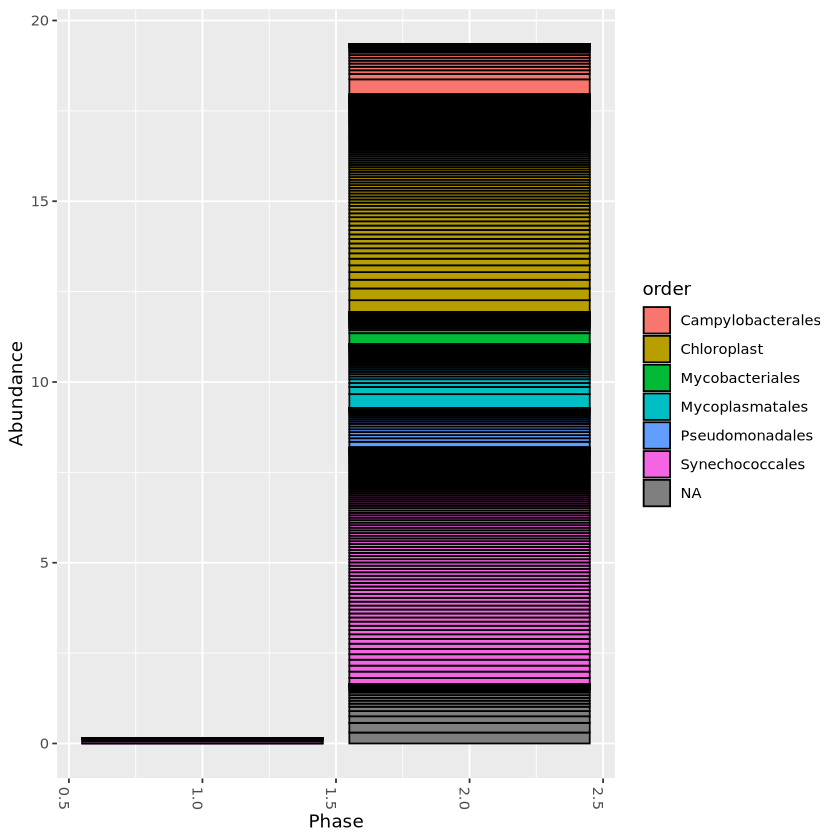

In [79]:
top20 <- names(sort(taxa_sums(ps_sub), decreasing=TRUE))[1:10]
ps.top20 <- transform_sample_counts(ps_sub, function(OTU) OTU/sum(OTU))
ps.top20 <- prune_taxa(top20, ps.top20)
plot_bar(ps.top20, x="Phase", fill="order")

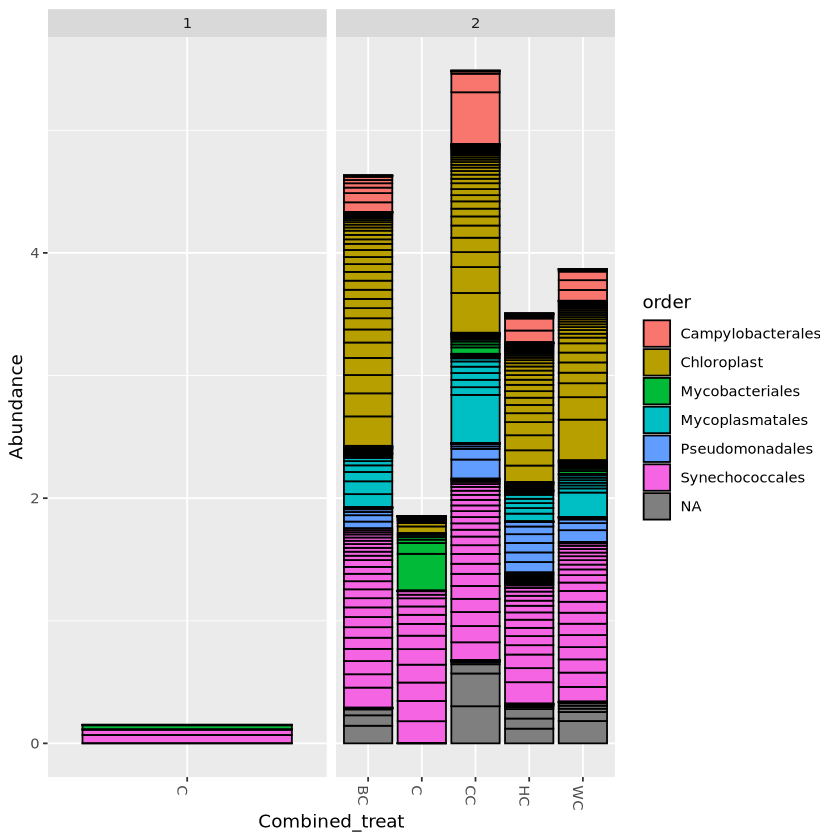

In [73]:
top20 <- names(sort(taxa_sums(ps_sub), decreasing=TRUE))[1:10]
ps.top20 <- transform_sample_counts(ps_sub, function(OTU) OTU/sum(OTU))
ps.top20 <- prune_taxa(top20, ps.top20)
plot_bar(ps.top20, x="Combined_treat", fill="order") + facet_wrap(~Phase, scales="free_x")

In [43]:
tax <- as(tax_table(ps), "matrix")

# Function to calculate classification rate
classification_rate <- function(x) {
  classified <- !is.na(x) &
    trimws(x) != "" &
    !grepl("unclassified|unknown|uncultured|unassigned",
           x, ignore.case = TRUE)

  mean(classified) * 100
}

# Calculate rate for each taxonomic rank
rates <- apply(tax, 2, classification_rate)

round(rates, 2)

domain  phylum   class   order  family   genus species 
  46.63   37.24   35.58   28.47   24.97   18.26    0.00

In [44]:

#isolate just bacteria
ps_bac=subset_taxa(ps, domain=="Bacteria")
ps_bac

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 66795 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 66795 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 66795 reference sequences ]

In [45]:
tax <- as(tax_table(ps_bac), "matrix")

# Function to calculate classification rate
classification_rate <- function(x) {
  classified <- !is.na(x) &
    trimws(x) != "" &
    !grepl("unclassified|unknown|uncultured|unassigned",
           x, ignore.case = TRUE)

  mean(classified) * 100
}

# Calculate rate for each taxonomic rank
rates <- apply(tax, 2, classification_rate)

round(rates, 2)

domain  phylum   class   order  family   genus species 
 100.00   79.58   75.97   60.54   53.06   38.67    0.00

In [59]:
# Subset samples
ps_sub <- subset_samples(ps, Phase_2_treat == "Cont")

# Remove taxa absent from the subset
ps_sub <- prune_taxa(taxa_sums(ps_sub) > 0, ps_sub)

ps_sub <- subset_taxa(ps, domain=="Bacteria")

In [47]:
head(ps)

ERROR: Error in x[seq_len(n)]: object of type 'S4' is not subsettable


In [52]:
head(sampleMetadata)

,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,Phase,Tissue,Concentration,⋯,Pooled_notes,Index_primers,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes
,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<int>,<chr>,<dbl>,⋯,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
2024_Both01_Both01_O1_gill,2024,BB,Both,1,Both,1,O1,2,gill,18.100,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,6.66,3.75,
2024_Both01_Both01_O1_gut,2024,BB,Both,1,Both,1,O1,2,gut,43.000,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,8.24,3.03,
2024_Both01_Null_O03_gill,2024,BNA,Both,1,NA,NA,O03,1,gill,0.980,⋯,,BFi-13,2026-07-08,3,7/10/26,,7/22/26,4.98,5.02,
2024_Both01_Null_O03_gut,2024,BNA,Both,1,NA,NA,O03,1,gut,0.886,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,5.80,4.31,Diluted final sample 1:3
2024_Both01_Warm05_O50_gill,2024,BW,Both,1,Warm,5,O50,2,gill,75.200,⋯,,BFi-13,2026-07-06,1,7/6/26,NA,NA,10.07,2.48,Diluted final sample 1:3
2024_Both01_Warm05_O50_gut,2024,BW,Both,1,Warm,5,O50,2,gut,46.900,⋯,,BFi-15,2026-07-03,2,7/3/26,NA,NA,7.40,3.38,Diluted final sample 1:3


In [49]:
sampleMetadata

ERROR: Error: object 'sampleMetadata' not found


In [63]:
ps_sub

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 66795 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 66795 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 66795 reference sequences ]

In [70]:
# Subset samples
ps_sub <- subset_samples(ps, Phase_2_treat == "Cont")

In [71]:
# Remove taxa absent from the subset
ps_sub <- prune_taxa(taxa_sums(ps_sub) > 0, ps_sub)

ps_sub <- subset_taxa(ps_sub, domain=="Bacteria")